# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Свіщенко Дарія Олександрівна  
**Група:** 3-9

**Дата:** 27.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.utils import to_categorical

try:
    from tensorflow.keras.preprocessing.text import Tokenizer
except ImportError:
    from keras.preprocessing.text import Tokenizer

### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
text = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""

print(text[:100])

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розві


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
text = text.replace("\ufeff", "")
maxWordsCount = 1000

tokenizer = Tokenizer(
    num_words=maxWordsCount,
    lower=True,
    split=' ',
    char_level=False,
    filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n—–«»„“”’…'
)

tokenizer.fit_on_texts([text])

print(len(tokenizer.word_index))
print(list(tokenizer.word_index.items())[:10])

35
[('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
res = np.array(tokenizer.texts_to_sequences([text])[0])
inp_words = 3

X = []
Y = []

for i in range(len(res) - inp_words):
    X.append(res[i:i + inp_words])
    Y.append(res[i + inp_words])

X = np.array(X)
Y = to_categorical(Y, num_classes=maxWordsCount)

print(X.shape)
print(Y.shape)
print(X[0])
print(np.argmax(Y[0]))

(49, 3)
(49, 1000)
[7 8 7]
8


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

параметр return_sequences=True у SimpleRNN потрібен для того, щоб шар повертав повну послідовність прихованих станів для кожного кроку послідовності, а не лише останній вихідний вектор. Наступний шар LSTM очікує на вході саме послідовність (3D-тензор), щоб обробити її крок за кроком.

In [5]:
model = Sequential([
    Embedding(maxWordsCount, 300, input_length=inp_words),
    SimpleRNN(128, activation='tanh', return_sequences=True),
    LSTM(128, activation='tanh'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(maxWordsCount, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [7]:
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=0)

print(history.history['loss'][-1])
print(history.history['accuracy'][-1])

1.4333430528640747
0.5510203838348389


### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

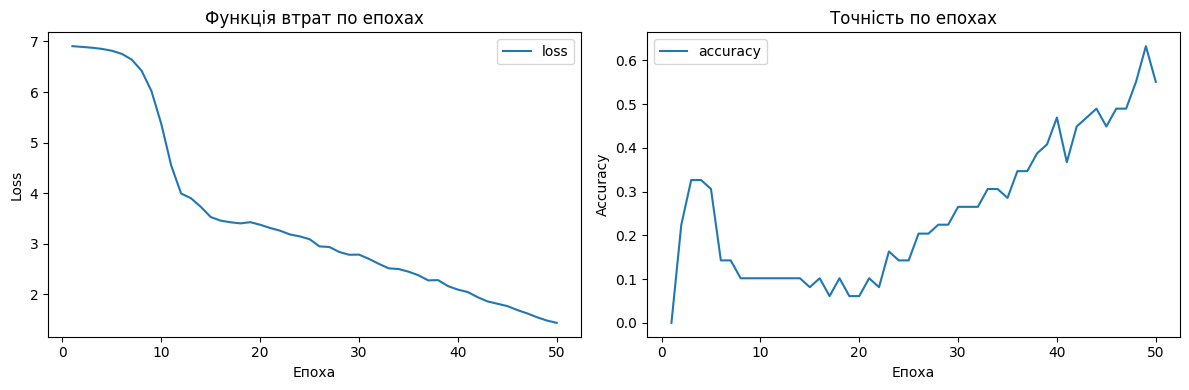

In [8]:
epochs_range = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history.history['loss'], label='loss')
axes[0].set_title('Функція втрат по епохах')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, history.history['accuracy'], label='accuracy')
axes[1].set_title('Точність по епохах')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [9]:
def buildPhrase(texts, str_len=20):
    seq = tokenizer.texts_to_sequences([texts])[0]
    if len(seq) < inp_words:
        return "Помилка: у початковій фразі менше ніж три відомі токеналізатору слова."

    result_words = texts.split()
    current_seq = list(seq[-inp_words:])

    for _ in range(str_len):
        x_input = np.array([current_seq])
        pred = model.predict(x_input, verbose=0)
        next_idx = int(np.argmax(pred[0]))
        next_word = tokenizer.index_word.get(next_idx)
        if not next_word:
            break
        result_words.append(next_word)
        current_seq = current_seq[1:] + [next_idx]

    return " ".join(result_words)


generated_text = buildPhrase("Думи мої думи", 20)
print(generated_text)

Думи мої думи мої лихо мої лихо вами лихо вами на на на сміх поливали поливали чом не не не в в в


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [10]:
%pip install -q keras-tuner
import keras_tuner as kt

### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [11]:
def build_model(hp):
    embedding_dim = hp.Int('embedding_dim', min_value=128, max_value=512, step=64)
    rnn_units = hp.Int('rnn_units', min_value=64, max_value=256, step=64)
    lstm_units = hp.Int('lstm_units', min_value=64, max_value=256, step=64)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    dense_units = hp.Int('dense_units', min_value=64, max_value=256, step=64)
    optimizer_name = hp.Choice('optimizer', values=['adam', 'rmsprop'])

    model = Sequential([
        Embedding(maxWordsCount, embedding_dim, input_length=inp_words),
        SimpleRNN(rnn_units, activation='tanh', return_sequences=True),
        LSTM(lstm_units, activation='tanh'),
        Dropout(dropout_rate),
        Dense(dense_units, activation='relu'),
        Dense(maxWordsCount, activation='softmax')
    ])

    model.compile(
        optimizer=optimizer_name,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [12]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction'
)

tuner.search(X, Y, epochs=10, batch_size=32)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

for param in ['embedding_dim', 'rnn_units', 'lstm_units', 'dropout_rate', 'dense_units', 'optimizer']:
    print(f"{param}: {best_hp.get(param)}")

Trial 10 Complete [00h 00m 06s]
accuracy: 0.3877550959587097

Best accuracy So Far: 0.40816327929496765
Total elapsed time: 00h 00m 57s
embedding_dim: 448
rnn_units: 64
lstm_units: 128
dropout_rate: 0.1
dense_units: 64
optimizer: adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [13]:
best_model = tuner.hypermodel.build(best_hp)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50, verbose=0)

best_model.summary()
print(best_history.history['loss'][-1])
print(best_history.history['accuracy'][-1])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 448)         │       448,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 64)          │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │        65,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,958,714 (7.47 MB)

 Trainable params: 652,904 (2.49 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,305,810 (4.98 MB)

2.266747236251831
0.4285714328289032


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

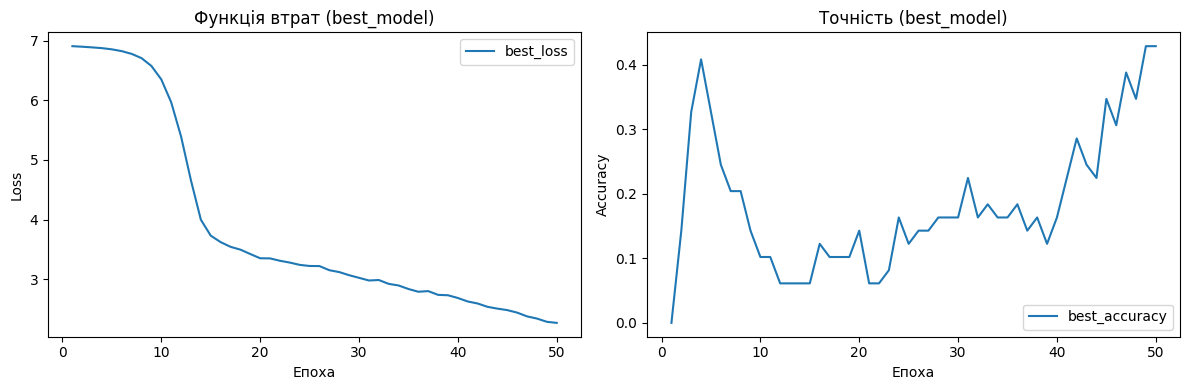

Модель       | Final Loss   | Final Accuracy 
---------------------------------------------
model        | 1.4333       | 0.5510         
best_model   | 2.2667       | 0.4286         

Генерація базовою моделлю (model):
Думи мої думи мої лихо мої лихо вами лихо вами на на на сміх поливали поливали чом не не не в в в

Генерація моделлю після підбору (best_model):
Думи мої думи вас лихо лихо не на як в вас в не не як в в в не не як в в


In [14]:
epochs_range = range(1, len(best_history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, best_history.history['loss'], label='best_loss')
axes[0].set_title('Функція втрат (best_model)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, best_history.history['accuracy'], label='best_accuracy')
axes[1].set_title('Точність (best_model)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"{'Модель':<12} | {'Final Loss':<12} | {'Final Accuracy':<15}")
print("-" * 45)
print(f"{'model':<12} | {history.history['loss'][-1]:<12.4f} | {history.history['accuracy'][-1]:<15.4f}")
print(f"{'best_model':<12} | {best_history.history['loss'][-1]:<12.4f} | {best_history.history['accuracy'][-1]:<15.4f}")

def buildPhrase(texts, str_len=20, target_model=model):
    seq = tokenizer.texts_to_sequences([texts])[0]
    if len(seq) < inp_words:
        return "Помилка: у початковій фразі менше ніж три відомі токеналізатору слова."

    result_words = texts.split()
    current_seq = list(seq[-inp_words:])

    for _ in range(str_len):
        x_input = np.array([current_seq])
        pred = target_model.predict(x_input, verbose=0)
        next_idx = int(np.argmax(pred[0]))
        next_word = tokenizer.index_word.get(next_idx)
        if not next_word:
            break
        result_words.append(next_word)
        current_seq = current_seq[1:] + [next_idx]

    return " ".join(result_words)

text_model = buildPhrase("Думи мої думи", 20, model)
text_best = buildPhrase("Думи мої думи", 20, best_model)

print("\nГенерація базовою моделлю (model):")
print(text_model)

print("\nГенерація моделлю після підбору (best_model):")
print(text_best)

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

У побудованій рекурентній мережі шар Embedding перетворює індекси слів у щільні векторні представлення, SimpleRNN обробляє послідовність крок за кроком і передає приховані стани далі, LSTM фіксує довші контекстні залежності, а Dropout зменшує перенавчання. Початкова модель model після навчання досягла значень loss = 1.4333 та accuracy = 0.5510. Під час підбору гіперпараметрів Keras Tuner обрав embedding_dim = 448, rnn_units = 64, lstm_units = 128, dropout_rate = 0.1, dense_units = 64 та оптимізатор adam. Після навчання best_model її фінальні показники (loss = 2.2667, accuracy = 0.4206) виявилися гіршими за базову модель через обмежену кількість випробувань (max_trials=10), невелику кількість епох підбору (10) та малий обсяг вибірки. Згенерований текст складається зі слів вихідного вірша, але має повтори та слабку зв'язність. Для стабільнішої роботи й змістовнішої генерації потрібен значно більший текстовий корпус, на якому модель зможе вивчити різноманітні контексти без зациклення на найчастіших словах.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.